# GEN eval violins — method × training seed × eval config

Per-episode eval returns of the battery-capacity generalisation (GEN) snapshots, split along
four axes:

| Axis | Read from |
|---|---|
| `AXIS.METHOD` | the source's `method`, checked against the `"algorithm"` its eval sidecar JSON records |
| `AXIS.GEN_CFG` | the source's `gen_cfg` |
| `AXIS.TRAIN_SEED` | `seed` of the RLlib config the checkpoint's training run saved to `param_space.json` (that run is found via the checkpoint path in the eval sidecar JSON); without that file, `training_params.common.seed` of the trial-YAML copy beside the eval CSV, else its top-level `seed` |
| `AXIS.EVAL_CFG` | the held-out eval-config result directory `<name>_eval_<i>` |

Each entry of `AXIS_ORDERS` lays them out: its first axis gets one figure per value, the other
three nest along the x-axis from the broadest group down to a single violin. A violin holds the
episodes of one (method, gen config, training seed, eval config) cell; the y-axis is the
metric, by default the episode return `total_reward`.

The per-training-seed eval runs come from `tools.snapshot.submit_snapshot --common-seed N`,
which appends `_cseed<N>` to the run directory. For a `_pp` source, the **base snapshot** (same
path without `_pp`) is read as well, restricted to its eval runs on `BASE_SNAPSHOT_EVAL_SEED`
(42): its own training run joins the training-seed axis. Both seeds are read from each run's
own files, never from a directory name. Rule-based runs (`runs/eval_rbc_*`) carry no training
seed and are not read.

**Main inputs:** `SOURCES` and `AXIS_ORDERS` in the next-but-one cell. Every artefact is saved
next to the notebook as `<date>_<time>_out_<i>.<format>`.

In [1]:
from enum import Enum


# Values are the trial YAML's `algorithm` ids, so a source's method can be checked against the
# algorithm its eval results record.
class METHOD(Enum):
    SAC = "sac"
    PPO = "ppo"
    DREAMER = "dreamerv3"


class GEN_CFG(Enum):
    SPEC_15 = "15 kWh"
    SPEC_17 = "17 kWh"
    GEN_DISTR = "Gen. distr"
    GEN_N_WAY = "N-way"


# The four axes a violin is keyed by; each value names the matching column of `episodes`.
class AXIS(Enum):
    METHOD = "method"
    GEN_CFG = "gen_cfg"
    TRAIN_SEED = "train_seed"
    EVAL_CFG = "eval_cfg"


METHOD_LABELS = {METHOD.SAC: "SAC", METHOD.PPO: "PPO", METHOD.DREAMER: "DreamerV3"}

In [2]:

# --- Main input ---------------------------------------------------------------------
# One entry per snapshot: its directory (absolute, or relative to the repo root), the method it
# was trained with and its training config. An optional "eval-kind" ("eval-ray" by default, or
# "eval-sb") picks which runs/eval_* directories are read.
SOURCES = [
    {
        "path": "snapshots/20260714_161830_gen_battery_lin_so_only_17kW_sac_cp_pp",
        "method": METHOD.SAC,
        "gen_cfg": GEN_CFG.SPEC_17,
    },
    {
        "path": "snapshots/20260714_235241_gen_battery_lin_so_only_15kW_sac_cp_pp",
        "method": METHOD.SAC,
        "gen_cfg": GEN_CFG.SPEC_15,
    },
    {
        "path": "snapshots/20260714_162614_gen_battery_lin_so_all_sac_v2_pp",
        "method": METHOD.SAC,
        "gen_cfg": GEN_CFG.GEN_N_WAY,
    },
    {
        "path": "snapshots/20260714_165943_gen_battery_lin_capacity_sampled_sac_pp",
        "method": METHOD.SAC,
        "gen_cfg": GEN_CFG.GEN_DISTR,
    },
    {
        "path": "snapshots/20260714_235444_gen_battery_lin_so_only_17kW_ppo_cp_pp",
        "method": METHOD.PPO,
        "gen_cfg": GEN_CFG.SPEC_17,
    },
    {
        "path": "snapshots/20260714_235342_gen_battery_lin_so_only_15kW_ppo_cp_pp",
        "method": METHOD.PPO,
        "gen_cfg": GEN_CFG.SPEC_15,
    },
    {
        "path": "snapshots/20260714_235542_gen_battery_lin_so_all_ppo_v2_cp_pp",
        "method": METHOD.PPO,
        "gen_cfg": GEN_CFG.GEN_N_WAY,
    },
    {
        "path": "snapshots/20260714_235647_gen_battery_lin_capacity_sampled_ppo_cp_pp",
        "method": METHOD.PPO,
        "gen_cfg": GEN_CFG.GEN_DISTR,
    },
    {
        "path": "snapshots/20260714_225444_gen_battery_lin_so_only_17kW_dreamer_pp",
        "method": METHOD.DREAMER,
        "gen_cfg": GEN_CFG.SPEC_17,
    },
    {
        "path": "snapshots/20260714_225342_gen_battery_lin_so_only_15kW_dreamer_pp",
        "method": METHOD.DREAMER,
        "gen_cfg": GEN_CFG.SPEC_15,
    },
    {
        "path": "snapshots/20260714_225542_gen_battery_lin_so_all_dreamer_v2_pp",
		"method": METHOD.DREAMER,
		"gen_cfg": GEN_CFG.GEN_N_WAY,	
	},
    {
		"path": "snapshots/20260714_225647_gen_battery_lin_capacity_sampled_dreamer_pp",
		"method": METHOD.DREAMER,
		"gen_cfg": GEN_CFG.GEN_DISTR,
	}
]

# A source whose path ends in `_pp` also reads its base snapshot (same path without `_pp`),
# but only the base eval runs on this eval seed; their training seed joins the training-seed
# axis. None reads the listed snapshots only.
BASE_SNAPSHOT_EVAL_SEED: int | None = 42

# Layout, one figure set per entry:
#   (figure axis, broadest x-axis group, x slot, coloured violins dodged within a slot)
AXIS_ORDERS = [
    # (AXIS.GEN_CFG, AXIS.TRAIN_SEED, AXIS.METHOD, AXIS.EVAL_CFG),
    (AXIS.GEN_CFG, AXIS.METHOD, AXIS.TRAIN_SEED, AXIS.EVAL_CFG),
]

METRICS = ("total_reward",)  # the eval CSVs also carry "cum_E_kWh" and "cum_price_EUR"

# Display names of the held-out eval configs, keyed by the `eval_<i>` suffix of their result
# directory; the dict order is the x-axis order. Unlisted configs keep their `eval_<i>` key.
EVAL_CFG_LABELS = {
    "eval_1": "12 kWh",
    "eval_2": "16 kWh",
    "eval_3": "22 kWh",
}

# Axis names: beside their row of x-axis labels, and as the colour legend's title.
AXIS_TITLES = {
    AXIS.METHOD: "Method",
    AXIS.GEN_CFG: "Training config",
    AXIS.TRAIN_SEED: "Training seed",
    AXIS.EVAL_CFG: "Eval. capacity",
}

# Eval seeds to keep (the seed each eval run records in its sidecar JSON); None keeps all.
# Several kept seeds pool their episodes into one violin per cell.
EVAL_SEEDS: list[int] | None = None

# Axis values dropped from every figure and table, e.g. {AXIS.TRAIN_SEED: [97], AXIS.EVAL_CFG: ["eval_3"]}.
EXCLUDE: dict[AXIS, list] = {}

# Violin colours per value of whichever axis is the narrowest x-axis level. METHOD and GEN_CFG keep
# the colours of the earlier thesis figures; an axis left out gets a default (see the plotting cell).
AXIS_PALETTES = {
    AXIS.METHOD: {METHOD.SAC: "#75aef4", METHOD.PPO: "#f1bd2d", METHOD.DREAMER: "#f1652d"},
    AXIS.GEN_CFG: {
        GEN_CFG.SPEC_15: "#cc75f4",
        GEN_CFG.SPEC_17: "#75aef4",
        GEN_CFG.GEN_DISTR: "#89f0cc",
        GEN_CFG.GEN_N_WAY: "#f1bd2d",
    },
}

# One y-range for all figures of a metric and order, so the figures compare at a glance.
SHARE_Y = True

In [3]:
from datetime import datetime
from pathlib import Path


# Walk upwards from the cwd until the directory containing snapshots/ is found, so the
# notebook runs both from thesis_eval/ and from the repo root.
def _find_repo_root() -> Path:
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "snapshots").is_dir():
            return candidate
    raise FileNotFoundError("No 'snapshots/' directory found upwards of the cwd — run inside the repo.")


REPO_ROOT = _find_repo_root()

# VS Code exposes the notebook path; a plain Jupyter kernel starts in the notebook's directory.
OUT_DIR = Path(globals()["__vsc_ipynb_file__"]).parent if "__vsc_ipynb_file__" in globals() else Path.cwd()
OUT_RUN_STAMP = datetime.now().strftime("%Y%m%d_%H%M%S")
out_index = 0  # incremented once per saved artefact; reset by re-running this cell


def next_out_path(file_format: str) -> Path:
    """Next '<date>_<time>_out_<i>.<file_format>' path in this notebook's directory."""
    global out_index
    out_index += 1
    return OUT_DIR / f"{OUT_RUN_STAMP}_out_{out_index}.{file_format}"

## Discover the eval results

One record per eval CSV, i.e. per (source, eval run, held-out eval config). Only deterministic
eval results (`eval_results/*_eval/`) in held-out eval-config directories (`*_eval_<i>`) are
read; training-config directories such as `battery_lin_cap_3` are skipped. A source without
eval results is reported and left out, so a snapshot whose evals are still pending does not
stop the notebook. A `_pp` source adds its base snapshot's eval runs on
`BASE_SNAPSHOT_EVAL_SEED`, and a line per snapshot lists the training seeds found there.
`EVAL_SEEDS` and `EXCLUDE` are applied here.

In [4]:
import json
import re
from collections import Counter

import yaml

EVAL_KINDS = ("eval-ray", "eval-sb")

# A held-out eval-config result directory ends in `_eval_<i>` (e.g. battery_lin_cap_eval_1);
# training-config directories (e.g. battery_lin_cap_3) do not match and are skipped.
_EVAL_CFG_DIR_PATTERN = re.compile(r"(?:^|_)eval_(\d+)$")


# Display order of an axis value: enum order for methods and gen configs, EVAL_CFG_LABELS order
# (then the `eval_<i>` index) for eval configs, numeric for training seeds.
def _axis_sort_key(axis: AXIS, value) -> tuple:
    if axis in (AXIS.METHOD, AXIS.GEN_CFG):
        return (list(type(value)).index(value),)
    if axis is AXIS.EVAL_CFG:
        labelled = list(EVAL_CFG_LABELS)
        if value in labelled:
            return (labelled.index(value), 0)
        return (len(labelled), int(value.removeprefix("eval_")))
    return (value,)


def ordered_values(axis: AXIS, values) -> list:
    return sorted(set(values), key=lambda value: _axis_sort_key(axis, value))


def axis_label(axis: AXIS, value) -> str:
    if axis is AXIS.METHOD:
        return METHOD_LABELS[value]
    if axis is AXIS.GEN_CFG:
        return value.value
    if axis is AXIS.EVAL_CFG:
        return EVAL_CFG_LABELS.get(value, value)
    return str(value)


# Maps a runs/eval_* directory to its eval kind — mirrors the run-id scheme
# tools/snapshot/submit_snapshot.py builds from --kind. Rule-based runs map to None.
def _run_dir_eval_kind(run_dir: Path) -> str | None:
    if run_dir.name.startswith("eval_rbc_"):
        return None
    if run_dir.name.startswith("eval_sb_"):
        return "eval-sb"
    return "eval-ray"


# Resolves a snapshot path (absolute, or relative to the repo root).
def _snapshot_dir(path: str | Path) -> Path:
    snapshot_dir = Path(path)
    return snapshot_dir if snapshot_dir.is_absolute() else REPO_ROOT / snapshot_dir


# Fallback training seed, from the trial-YAML copy the eval wrote beside its CSV (provenance.yaml
# names it): `training_params.common.seed`, else the top-level `seed` — the same fallback
# TrialConfig hands to TrainingParamConfig. Exact only without an eval `--seed` override, which
# rewrites that top-level seed in the copy.
def _trial_copy_train_seed(cfg_dir: Path) -> int | None:
    provenance_path = cfg_dir / "provenance.yaml"
    if not provenance_path.is_file():
        return None
    trial_name = ((yaml.safe_load(provenance_path.read_text()) or {}).get("trial_yaml") or {}).get("name")
    if trial_name is None or not (cfg_dir / trial_name).is_file():
        return None
    trial = yaml.safe_load((cfg_dir / trial_name).read_text()) or {}
    common = (trial.get("training_params") or {}).get("common") or {}
    seed = common.get("seed", trial.get("seed"))
    return None if seed is None else int(seed)


# Training seed of the evaluated checkpoint: the `seed` of the RLlib config its training run saved
# to param_space.json (run_train_ray.py). That run is the `runs/<train run>` directory of the
# checkpoint path the eval sidecar JSON records, looked up inside `snapshot_dir`; runs without
# param_space.json (e.g. SB3) fall back to the trial-YAML copy.
def _train_seed(snapshot_dir: Path, cfg_dir: Path, checkpoint_path: str | None) -> int | None:
    parts = Path(checkpoint_path).parts if checkpoint_path else ()
    if "runs" in parts[:-1]:
        train_run = parts[len(parts) - parts[::-1].index("runs")]
        param_space_path = snapshot_dir / "runs" / train_run / "param_space.json"
        if param_space_path.is_file():
            seed = json.loads(param_space_path.read_text()).get("seed")
            if seed is not None:
                return int(seed)
    return _trial_copy_train_seed(cfg_dir)


# One record per held-out eval-config CSV under `snapshot_dir`, tagged with the source's method and
# gen config plus the seeds and eval config the run recorded. `eval_seed` keeps only the eval runs
# on that seed (None keeps all).
def _discover_snapshot_records(snapshot_dir: Path, source: dict, eval_seed: int | None = None) -> list[dict]:
    eval_kind = source.get("eval-kind", "eval-ray")
    if eval_kind not in EVAL_KINDS:
        raise ValueError(f"'eval-kind' must be one of {EVAL_KINDS}, got {eval_kind!r}")

    records = []
    for run_dir in sorted((snapshot_dir / "runs").glob("eval_*")):
        if _run_dir_eval_kind(run_dir) != eval_kind:
            continue
        for csv_path in sorted(run_dir.glob("eval_results/*_eval/*/eval_*.csv")):
            match = _EVAL_CFG_DIR_PATTERN.search(csv_path.parent.name)
            if match is None:
                continue  # training-config result dir — not a held-out eval config
            sidecar_path = csv_path.with_suffix(".json")
            sidecar = json.loads(sidecar_path.read_text()) if sidecar_path.is_file() else {}
            if eval_seed is not None and sidecar.get("seed") != eval_seed:
                continue
            records.append({
                "snapshot": snapshot_dir.name, "run": run_dir.name, "csv": csv_path,
                AXIS.METHOD.value: source["method"],
                AXIS.GEN_CFG.value: source["gen_cfg"],
                AXIS.TRAIN_SEED.value: _train_seed(snapshot_dir, csv_path.parent, sidecar.get("checkpoint_path")),
                AXIS.EVAL_CFG.value: f"eval_{match.group(1)}",
                "eval_seed": sidecar.get("seed"),
                "algorithm": sidecar.get("algorithm"),
            })
    return records


eval_records: list[dict] = []
for source in SOURCES:
    source_name = f"{METHOD_LABELS[source['method']]} / {source['gen_cfg'].value}"
    snapshot_dir = _snapshot_dir(source["path"])
    if not snapshot_dir.is_dir():
        raise FileNotFoundError(f"Snapshot directory not found: {snapshot_dir}")
    records = _discover_snapshot_records(snapshot_dir, source)

    # A `_pp` source also reads its base snapshot, restricted to BASE_SNAPSHOT_EVAL_SEED.
    base_dir = snapshot_dir.with_name(snapshot_dir.name.removesuffix("_pp"))
    if BASE_SNAPSHOT_EVAL_SEED is not None and base_dir != snapshot_dir:
        if not base_dir.is_dir():
            print(f"note: {source_name}: base snapshot {base_dir.name} not found — only {snapshot_dir.name} is read.")
        else:
            base_records = _discover_snapshot_records(base_dir, source, eval_seed=BASE_SNAPSHOT_EVAL_SEED)
            if not base_records:
                print(f"WARNING: {source_name}: base snapshot {base_dir.name} has no eval results on eval seed "
                      f"{BASE_SNAPSHOT_EVAL_SEED}.")
            records += base_records

    if not records:
        print(f"WARNING: no eval results for {source_name} ({source['path']}) — absent from every figure and table.")
    other_algorithms = {record["algorithm"] for record in records} - {None, source["method"].value}
    if other_algorithms:
        print(f"WARNING: {source_name} is set to method '{source['method'].value}', but its eval results "
              f"record algorithm(s) {sorted(other_algorithms)} — check SOURCES.")
    for snapshot_name in dict.fromkeys(record["snapshot"] for record in records):
        snapshot_records = [record for record in records if record["snapshot"] == snapshot_name]
        train_seeds = sorted({record[AXIS.TRAIN_SEED.value] for record in snapshot_records} - {None})
        print(f"{source_name:<22} {len(snapshot_records):>3} eval CSVs, training seed(s) {train_seeds}  <-  {snapshot_name}")
    eval_records.extend(records)

for record in eval_records:
    if record[AXIS.TRAIN_SEED.value] is None or record["eval_seed"] is None:
        print(f"WARNING: could not resolve the training or eval seed of {record['csv']} — dropped")
eval_records = [
    record for record in eval_records
    if record[AXIS.TRAIN_SEED.value] is not None and record["eval_seed"] is not None
]
if not eval_records:
    raise FileNotFoundError("No eval CSVs with resolvable seeds were discovered.")

# Colours are assigned from the values found before any filter, so dropping a value never
# repaints the others.
discovered_values = {axis: [record[axis.value] for record in eval_records] for axis in AXIS}

if EVAL_SEEDS is not None:
    print(f"Keeping eval seed(s) {EVAL_SEEDS} (EVAL_SEEDS); discovered: {sorted({r['eval_seed'] for r in eval_records})}.")
    eval_records = [record for record in eval_records if record["eval_seed"] in EVAL_SEEDS]
for axis, excluded in EXCLUDE.items():
    print(f"Excluding {AXIS_TITLES[axis]} value(s) {excluded} (EXCLUDE).")
    eval_records = [record for record in eval_records if record[axis.value] not in excluded]
if not eval_records:
    raise ValueError(f"EVAL_SEEDS={EVAL_SEEDS} / EXCLUDE={EXCLUDE} removed every discovered CSV — nothing left to plot.")

# A cell with several CSVs (re-runs, or several eval seeds) pools their episodes into one violin.
cell_counts = Counter(tuple(record[axis.value] for axis in AXIS) for record in eval_records)
for cell, count in cell_counts.items():
    if count > 1:
        cell_name = ", ".join(f"{AXIS_TITLES[axis]} {axis_label(axis, value)}" for axis, value in zip(AXIS, cell))
        print(f"note: {count} eval CSVs pool into the violin of {cell_name}")

print(f"{len(eval_records)} eval CSVs from {len({record['run'] for record in eval_records})} eval runs.")

SAC / 17 kWh            12 eval CSVs, training seed(s) [46, 71, 97, 141]  <-  20260714_161830_gen_battery_lin_so_only_17kW_sac_cp_pp
SAC / 17 kWh             3 eval CSVs, training seed(s) [42]  <-  20260714_161830_gen_battery_lin_so_only_17kW_sac_cp
SAC / 15 kWh            12 eval CSVs, training seed(s) [46, 71, 97, 141]  <-  20260714_235241_gen_battery_lin_so_only_15kW_sac_cp_pp
SAC / 15 kWh             3 eval CSVs, training seed(s) [42]  <-  20260714_235241_gen_battery_lin_so_only_15kW_sac_cp
SAC / N-way             12 eval CSVs, training seed(s) [46, 71, 97, 141]  <-  20260714_162614_gen_battery_lin_so_all_sac_v2_pp
SAC / N-way              3 eval CSVs, training seed(s) [42]  <-  20260714_162614_gen_battery_lin_so_all_sac_v2
SAC / Gen. distr        12 eval CSVs, training seed(s) [46, 71, 97, 141]  <-  20260714_165943_gen_battery_lin_capacity_sampled_sac_pp
SAC / Gen. distr         3 eval CSVs, training seed(s) [42]  <-  20260714_165943_gen_battery_lin_capacity_sampled_sac
PPO / 17 k

## Load per-episode metrics

One row per episode, tagged with its four axis values and eval seed. The table counts the eval
configs found per training config, method and training seed — a gap is a missing eval run.

In [5]:
import pandas as pd

frames = []
for record in eval_records:
    csv_frame = pd.read_csv(record["csv"])
    missing = [metric for metric in METRICS if metric not in csv_frame.columns]
    if missing:
        print(f"note: {record['csv']} lacks {missing} — skipped in those figures")
    frame = csv_frame[[metric for metric in METRICS if metric in csv_frame.columns]].copy()
    for axis in AXIS:
        frame[axis.value] = record[axis.value]
    frame["eval_seed"] = record["eval_seed"]
    frames.append(frame)

episodes = pd.concat(frames, ignore_index=True)


# `frame` with each axis column turned into its display label and renamed to its AXIS_TITLES
# name, as an ordered categorical so groupby and sorting follow the axis order.
def labelled_episodes(frame: pd.DataFrame) -> pd.DataFrame:
    frame = frame.copy()
    for axis in AXIS:
        categories = dict.fromkeys(axis_label(axis, value) for value in ordered_values(axis, frame[axis.value]))
        frame[axis.value] = pd.Categorical(
            [axis_label(axis, value) for value in frame[axis.value]], categories=list(categories), ordered=True,
        )
    return frame.rename(columns={axis.value: AXIS_TITLES[axis] for axis in AXIS})


labelled = labelled_episodes(episodes)
(
    labelled.groupby([AXIS_TITLES[AXIS.GEN_CFG], AXIS_TITLES[AXIS.METHOD], AXIS_TITLES[AXIS.TRAIN_SEED]], observed=True)
    [AXIS_TITLES[AXIS.EVAL_CFG]].nunique()
    .unstack(AXIS_TITLES[AXIS.TRAIN_SEED])
)

Training seed              42  46  71  97  141
Training config Method                        
15 kWh          SAC         3   3   3   3    3
                PPO         3   3   3   3    3
                DreamerV3   3   3   3   3    3
17 kWh          SAC         3   3   3   3    3
                PPO         3   3   3   3    3
                DreamerV3   3   3   3   3    3
Gen. distr      SAC         3   3   3   3    3
                PPO         3   3   3   3    3
                DreamerV3   3   3   3   3    3
N-way           SAC         3   3   3   3    3
                PPO         3   3   3   3    3
                DreamerV3   3   3   3   3    3

## Violin plots

`violin_for_metric(metric, order)` draws one figure per value of the order's first axis and
nests the other three along the x-axis, extending the earlier sources-per-seed layout by one
level:

- **narrowest** level — dodged violins side by side in one x slot, each in its own colour (legend);
- **middle** level — one x slot per value, named by the x tick labels;
- **broadest** level — a labelled bracket under each group of slots.

The level names sit to the right of their label rows, and a value keeps its colour in every
figure. The dots are the individual episodes; every violin also carries a red **mean** dot and a
dashed **median** line.

The legend sits beside the axes for up to `LEGEND_BELOW_ABOVE_SLOTS` (4) x slots; with more it
moves **under the plot**, spread over enough columns to stay within `LEGEND_MAX_ROWS` (2) rows.
With `SHARE_Y` all figures of one metric and order share a y-range. The figures have no title
(the thesis caption names them) and are saved as `<date>_<time>_out_<i>.pdf`.

In [6]:
from math import ceil

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import display
from matplotlib.lines import Line2D

sns.set_theme(style="whitegrid", context="notebook")

METRIC_LABELS = {
    "total_reward": "Total reward per episode",
    "cum_E_kWh": "Net grid energy exchange [kWh]",
    "cum_price_EUR": "Cumulative energy price [EUR]",
}

# Default colours of an axis missing from AXIS_PALETTES: categorical hues in a fixed order whose
# neighbours stay apart under colour-vision deficiency, or — for the eval configs, an ordered
# quantity here (battery capacity) — evenly spaced steps of one light→dark blue ramp. The ramp
# stops at a mid blue so the black episode dots and median lines stay visible on every fill.
CATEGORICAL_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
ORDINAL_BLUE_RAMP = ["#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#2a78d6"]

# Stat markers drawn on top of each violin (replaces seaborn's faint inner box)
MEAN_COLOR = "#e34948"  # red dot
MEDIAN_COLOR = "#1a1a19"  # narrow dashed line
MEDIAN_DASH = (0, (4, 2))

# Legend placement: beside the axes while the x-axis is narrow, under the plot as soon as more
# than LEGEND_BELOW_ABOVE_SLOTS x slots are drawn (a wide figure wastes the side strip).
LEGEND_BELOW_ABOVE_SLOTS = 4
LEGEND_MAX_ROWS = 2  # a legend under the plot never grows past this many rows
LEGEND_BELOW_PAD = 6  # points between the lowest x-axis label row and the legend below it
LEGEND_FONT_SIZE = 16  # point size of the legend entry labels

# Horizontal packing, in units of one x slot (adjacent slots sit 1.0 apart):
#   DODGE_WIDTH      the share of a slot its narrowest-level violins split evenly between them,
#                    like seaborn's hue dodge; the remainder (1 - DODGE_WIDTH) separates two slots.
#   OUTER_GROUP_GAP  extra space between two broadest-level groups.
#   X_AXIS_MARGIN    space left between the axes edges and the outermost violins.
DODGE_WIDTH = 0.85
OUTER_GROUP_GAP = 0.5
X_AXIS_MARGIN = 0.02
STRIP_JITTER = 0.1  # half-width of the episode dots' jitter, as a fraction of one violin's width
INCH_PER_VIOLIN = 0.6
MIN_FIGURE_WIDTH = 8.0  # inches
FIGURE_HEIGHT = 6.0     # inches

# Label rows under the x-axis, in points.
ROW_GAP = 5            # space between the tick labels and the bracket below them
BRACKET_TICK = 4       # height of a bracket's end ticks
BRACKET_LABEL_GAP = 2  # space between a bracket and its label
ROW_TITLE_GAP = 10     # space between the axes' right edge and a row's level name
BRACKET_COLOR = "0.35"
SEPARATOR_COLOR = "0.85"  # vertical rule between two broadest-level groups


# Colour per value of `axis`, covering every value discovered before the filters.
def axis_palette(axis: AXIS) -> dict:
    values = ordered_values(axis, discovered_values[axis])
    if axis in AXIS_PALETTES:
        missing = [axis_label(axis, value) for value in values if value not in AXIS_PALETTES[axis]]
        if missing:
            raise ValueError(f"AXIS_PALETTES[{axis}] has no colour for {missing}")
        return AXIS_PALETTES[axis]
    if axis is AXIS.EVAL_CFG and len(values) <= len(ORDINAL_BLUE_RAMP):
        steps = np.linspace(0, len(ORDINAL_BLUE_RAMP) - 1, len(values)).round().astype(int)
        return {value: ORDINAL_BLUE_RAMP[step] for value, step in zip(values, steps)}
    if len(values) > len(CATEGORICAL_COLORS):
        raise ValueError(f"{len(values)} values on {axis} exceed the {len(CATEGORICAL_COLORS)} default colours — "
                         "set AXIS_PALETTES for it.")
    return dict(zip(values, CATEGORICAL_COLORS))


# x layout of one figure: the centre of every (broadest, middle) slot, and of every violin dodged
# inside it — the same even split seaborn's hue dodge uses.
def _x_layout(levels: list[list]) -> tuple[dict, dict, float]:
    outer_values, middle_values, inner_values = levels
    outer_step = len(middle_values) + OUTER_GROUP_GAP
    slots = {
        (outer, middle): outer_index * outer_step + middle_index
        for outer_index, outer in enumerate(outer_values)
        for middle_index, middle in enumerate(middle_values)
    }
    violin_width = DODGE_WIDTH / len(inner_values)
    violins = {
        (outer, middle, inner): slot_x - DODGE_WIDTH / 2 + violin_width * (inner_index + 0.5)
        for (outer, middle), slot_x in slots.items()
        for inner_index, inner in enumerate(inner_values)
    }
    return slots, violins, violin_width


# (first slot x, last slot x) of every broadest-level group.
def _outer_spans(slots: dict) -> dict:
    spans = {}
    for (outer, _), x in slots.items():
        first, last = spans.get(outer, (x, x))
        spans[outer] = (min(first, x), max(last, x))
    return spans


# Draws one figure's violins, episode dots, mean/median markers and slot tick labels. The label
# rows and the legend follow in violin_for_metric, once the y-range is final.
def _draw_figure(data: pd.DataFrame, metric: str, order: tuple, palette: dict) -> dict:
    x_axes = order[1:]
    inner_axis = x_axes[2]
    levels = [ordered_values(axis, data[axis.value]) for axis in x_axes]
    slots, violins, violin_width = _x_layout(levels)
    cells = list(data[[axis.value for axis in x_axes]].itertuples(index=False, name=None))
    data = data.assign(
        x=[violins[cell] for cell in cells],
        hue=[axis_label(inner_axis, value) for value in data[inner_axis.value]],
    )
    hue_palette = {axis_label(inner_axis, value): palette[value] for value in levels[2]}

    # Each violin is drawn at its own dodged centre on a numeric x-axis. seaborn sizes violins and
    # jitter in multiples of the smallest gap between those centres (native_scale), so that gap
    # is divided out to keep both in x data units.
    # Link: https://github.com/mwaskom/seaborn/blob/v0.13.2/seaborn/categorical.py#L433-L445
    unique_x = np.unique(data["x"])
    native_width = np.diff(unique_x).min() if len(unique_x) > 1 else 1.0

    fig, ax = plt.subplots(figsize=(max(MIN_FIGURE_WIDTH, INCH_PER_VIOLIN * len(violins)), FIGURE_HEIGHT))
    sns.violinplot(
        data=data, x="x", y=metric, hue="hue", hue_order=list(hue_palette), palette=hue_palette,
        native_scale=True, dodge=False, width=violin_width / native_width,
        # common_norm: one density scale for the whole figure, so every violin encloses the same
        # area; without it seaborn normalises each hue level on its own.
        # Link: https://seaborn.pydata.org/generated/seaborn.violinplot.html
        density_norm="area", common_norm=True,
        inner=None,  # the stat markers below replace seaborn's faint inner box
        linewidth=1.0, saturation=1.0, ax=ax,
    )
    hue_handles, hue_labels = ax.get_legend_handles_labels()  # seaborn's hue entries, re-placed later
    ax.get_legend().remove()
    sns.stripplot(
        data=data, x="x", y=metric, native_scale=True, color="0.1",
        size=3, alpha=0.6, jitter=STRIP_JITTER * violin_width / native_width, ax=ax,
    )

    # Overlays each violin's mean (red dot) and median (narrow dashed line).
    stats = data.groupby("x")[metric].agg(["mean", "median"])
    half_width = 0.9 * violin_width / 2
    ax.hlines(stats["median"], stats.index - half_width, stats.index + half_width,
              color=MEDIAN_COLOR, linewidth=0.9, linestyle=MEDIAN_DASH, zorder=5)
    ax.scatter(stats.index, stats["mean"], color=MEAN_COLOR, s=54, edgecolor="white", linewidth=1.5, zorder=6)

    outer_spans = list(_outer_spans(slots).values())
    for (_, previous_last), (next_first, _) in zip(outer_spans, outer_spans[1:]):
        ax.axvline((previous_last + next_first) / 2, color=SEPARATOR_COLOR, linewidth=0.8, zorder=0)

    ax.set_xticks(list(slots.values()), labels=[axis_label(x_axes[1], middle) for _, middle in slots])
    # Trim the padding seaborn leaves left of the first and right of the last violin.
    ax.set_xlim(-DODGE_WIDTH / 2 - X_AXIS_MARGIN, max(slots.values()) + DODGE_WIDTH / 2 + X_AXIS_MARGIN)
    ax.set_xlabel("")
    ax.set_ylabel(METRIC_LABELS.get(metric, metric))
    ax.grid(axis="x", visible=False)
    sns.despine(ax=ax)

    missing = [
        " / ".join(axis_label(axis, value) for axis, value in zip(x_axes, cell))
        for cell in violins if cell not in set(cells)
    ]
    return {"fig": fig, "ax": ax, "slots": slots, "hue_handles": hue_handles, "hue_labels": hue_labels,
            "missing": missing}


# Distance from the axes' bottom edge down to the lowest of `artists`, in points.
def _depth_below_axes(ax, artists: list) -> float:
    renderer = ax.figure.canvas.get_renderer()
    lowest = min(artist.get_window_extent(renderer).y0 for artist in artists)
    return (ax.get_window_extent(renderer).y0 - lowest) * 72 / ax.figure.dpi


# Points below the axes' bottom edge -> axes-fraction y (negative: under the axes).
def _axes_y(ax, depth: float) -> float:
    return -depth / (ax.get_window_extent(ax.figure.canvas.get_renderer()).height * 72 / ax.figure.dpi)


# Level name to the right of a label row whose top sits `depth` points under the axes.
def _row_title(ax, depth: float, axis: AXIS) -> None:
    axes_width = ax.get_window_extent(ax.figure.canvas.get_renderer()).width * 72 / ax.figure.dpi
    ax.text(1 + ROW_TITLE_GAP / axes_width, _axes_y(ax, depth), AXIS_TITLES[axis], transform=ax.transAxes,
            ha="left", va="top", fontstyle="italic", color="0.3", clip_on=False)


# Names the slot tick labels' level, then draws a bracket under every broadest-level group with
# the group's value below it, placed under the measured tick labels. Returns how far below the
# axes the rows reach, in points.
def _draw_label_rows(ax, order: tuple, slots: dict) -> float:
    ax.figure.canvas.draw()  # tick labels only get their extents once drawn
    renderer = ax.figure.canvas.get_renderer()
    tick_labels = [label for label in ax.get_xticklabels() if label.get_text()]
    tick_top = (ax.get_window_extent(renderer).y0 - max(label.get_window_extent(renderer).y1 for label in tick_labels))
    _row_title(ax, tick_top * 72 / ax.figure.dpi, order[2])

    bracket_top = _depth_below_axes(ax, tick_labels) + ROW_GAP
    bracket_bottom = bracket_top + BRACKET_TICK
    transform = ax.get_xaxis_transform()  # x in data units, y in axes fraction
    labels = []
    for outer, (first, last) in _outer_spans(slots).items():
        left, right = first - DODGE_WIDTH / 2, last + DODGE_WIDTH / 2
        ax.plot([left, left, right, right],
                [_axes_y(ax, bracket_top), _axes_y(ax, bracket_bottom), _axes_y(ax, bracket_bottom), _axes_y(ax, bracket_top)],
                transform=transform, color=BRACKET_COLOR, linewidth=0.9, clip_on=False)
        labels.append(ax.text((left + right) / 2, _axes_y(ax, bracket_bottom + BRACKET_LABEL_GAP),
                              axis_label(order[1], outer), transform=transform, ha="center", va="top", clip_on=False))
    _row_title(ax, bracket_bottom + BRACKET_LABEL_GAP, order[1])
    return _depth_below_axes(ax, labels)


# Places the legend outside the axes: to the right for a narrow x-axis, but under the label rows
# once the slot fan-out makes the figure wide. Below the plot the entries go on one row when that
# row fits the figure width, else on `ceil(n / LEGEND_MAX_ROWS)` columns — so the legend never
# exceeds LEGEND_MAX_ROWS rows.
def _draw_legend(ax, handles: list, labels: list[str], title: str, slot_count: int, rows_depth: float) -> None:
    if slot_count <= LEGEND_BELOW_ABOVE_SLOTS:
        ax.legend(handles=handles, labels=labels, title=title, frameon=False,
                  loc="upper left", bbox_to_anchor=(1.01, 1.0), borderaxespad=0.0,
                  fontsize=LEGEND_FONT_SIZE, title_fontsize=LEGEND_FONT_SIZE)
        return

    anchor_y = _axes_y(ax, rows_depth + LEGEND_BELOW_PAD)
    figure_width = ax.figure.get_window_extent().width
    column_counts = dict.fromkeys([len(handles), ceil(len(handles) / LEGEND_MAX_ROWS)])  # widest first
    for index, columns in enumerate(column_counts):
        legend = ax.legend(handles=handles, labels=labels, title=title, frameon=False, loc="upper center",
                           bbox_to_anchor=(0.5, anchor_y), borderaxespad=0.0, ncol=columns,
                           fontsize=LEGEND_FONT_SIZE, title_fontsize=LEGEND_FONT_SIZE)
        legend_width = legend.get_window_extent(ax.figure.canvas.get_renderer()).width
        if legend_width <= figure_width or index == len(column_counts) - 1:
            return  # fits the figure width, or this is the LEGEND_MAX_ROWS-row fallback


# One figure per value of order[0], with order[1:] nested along the x-axis (broadest first). Each
# figure is saved as a PDF next to this notebook and shown inline.
def violin_for_metric(metric: str, order: tuple) -> None:
    if len(order) != len(AXIS) or set(order) != set(AXIS):
        raise ValueError(f"An axis order must name every AXIS exactly once, got {order}")
    data = episodes.dropna(subset=[metric]) if metric in episodes.columns else episodes.iloc[0:0]
    if data.empty:
        print(f"no data for '{metric}' — figures skipped")
        return
    figure_axis, inner_axis = order[0], order[3]
    palette = axis_palette(inner_axis)

    figures = {
        value: _draw_figure(data[data[figure_axis.value] == value], metric, order, palette)
        for value in ordered_values(figure_axis, data[figure_axis.value])
    }
    y_limits = [figure["ax"].get_ylim() for figure in figures.values()]
    shared_y_limits = (min(bottom for bottom, _ in y_limits), max(top for _, top in y_limits))

    stat_handles = [
        Line2D([], [], color=MEAN_COLOR, marker="o", linestyle="none", markersize=10,
               markeredgewidth=1.5, label="mean"),
        Line2D([], [], color=MEDIAN_COLOR, linewidth=0.9, linestyle=MEDIAN_DASH, label="median"),
    ]
    for value, figure in figures.items():
        fig, ax = figure["fig"], figure["ax"]
        # Freeze the y-range before the brackets are added, so they cannot trigger an autoscale.
        ax.set_ylim(shared_y_limits if SHARE_Y else ax.get_ylim())
        rows_depth = _draw_label_rows(ax, order, figure["slots"])
        _draw_legend(
            ax,
            figure["hue_handles"] + stat_handles,
            figure["hue_labels"] + [handle.get_label() for handle in stat_handles],
            AXIS_TITLES[inner_axis], len(figure["slots"]), rows_depth,
        )

        pdf_path = next_out_path("pdf")
        fig.savefig(pdf_path, bbox_inches="tight")
        x_layout = " › ".join(AXIS_TITLES[axis] for axis in order[1:])
        print(f"{AXIS_TITLES[figure_axis]}: {axis_label(figure_axis, value)}  |  {metric}  |  x: {x_layout}  ->  saved {pdf_path}")
        if figure["missing"]:
            print(f"  note: no episodes for {len(figure['missing'])} violin(s), left empty: {', '.join(figure['missing'])}")
        display(fig)
        plt.close(fig)

Training config: 15 kWh  |  total_reward  |  x: Method › Training seed › Eval. capacity  ->  saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/20261028_131344_out_1.pdf


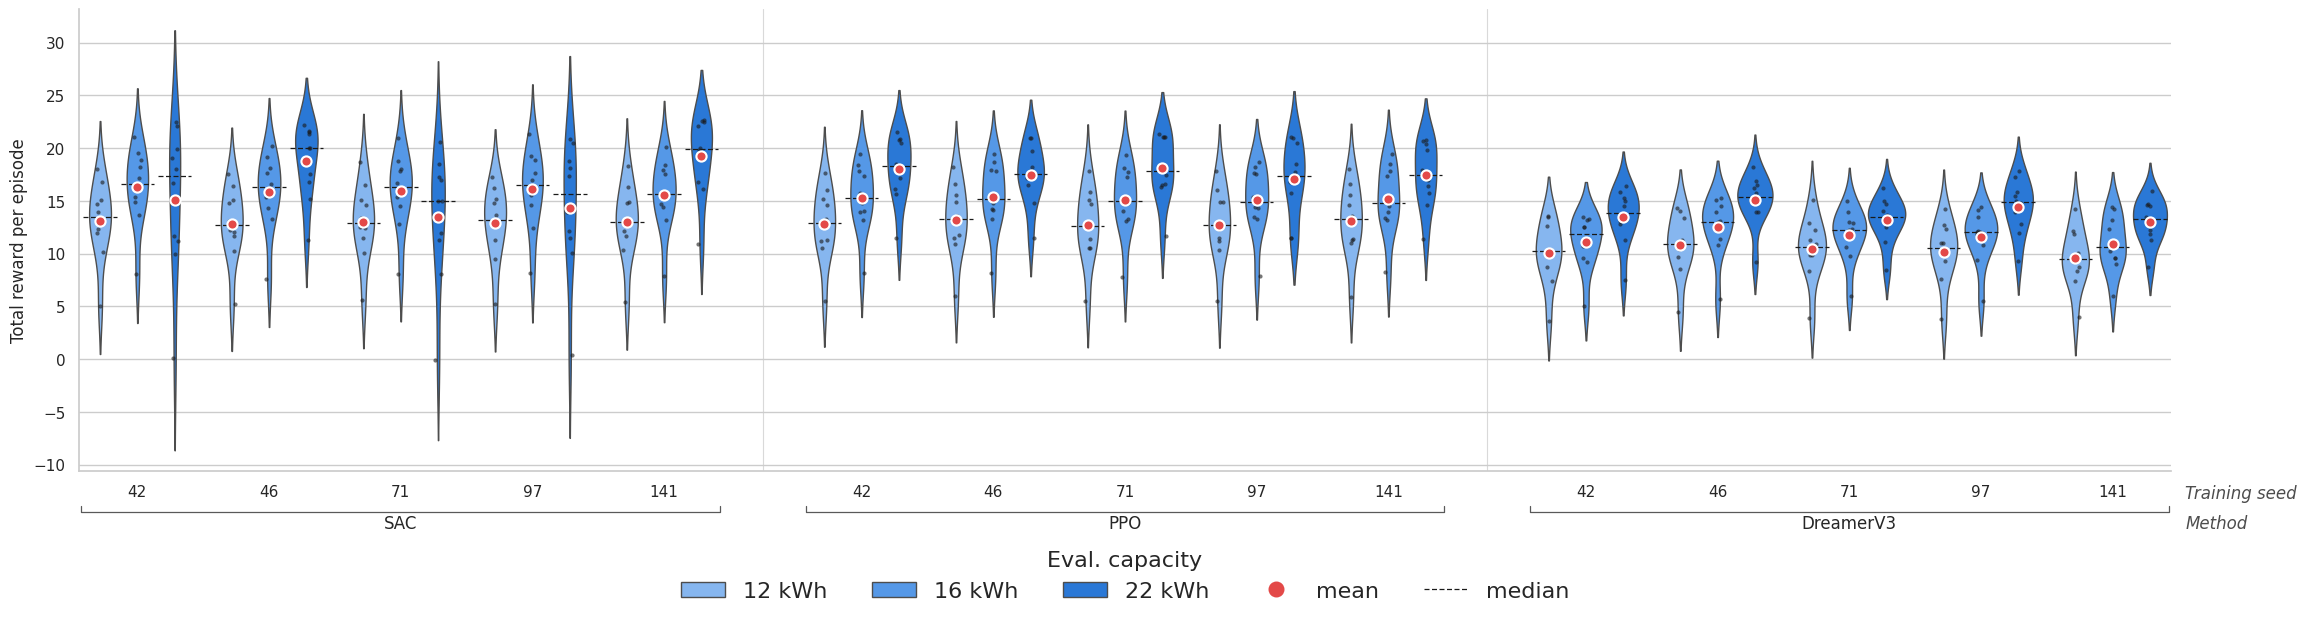

Training config: 17 kWh  |  total_reward  |  x: Method › Training seed › Eval. capacity  ->  saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/20261028_131344_out_2.pdf


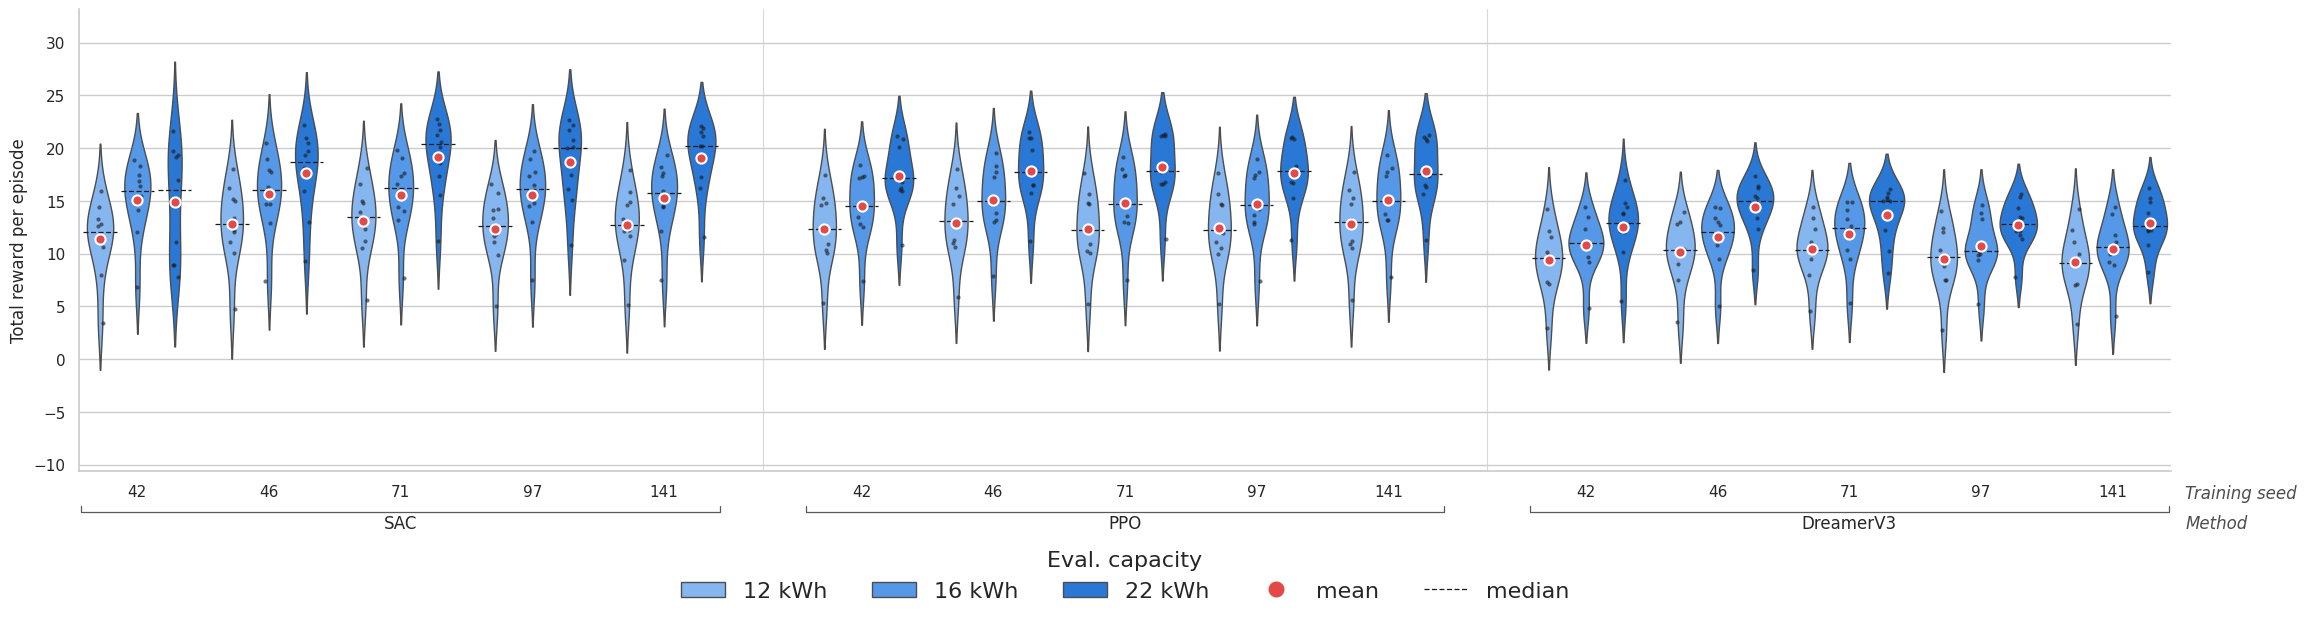

Training config: Gen. distr  |  total_reward  |  x: Method › Training seed › Eval. capacity  ->  saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/20261028_131344_out_3.pdf


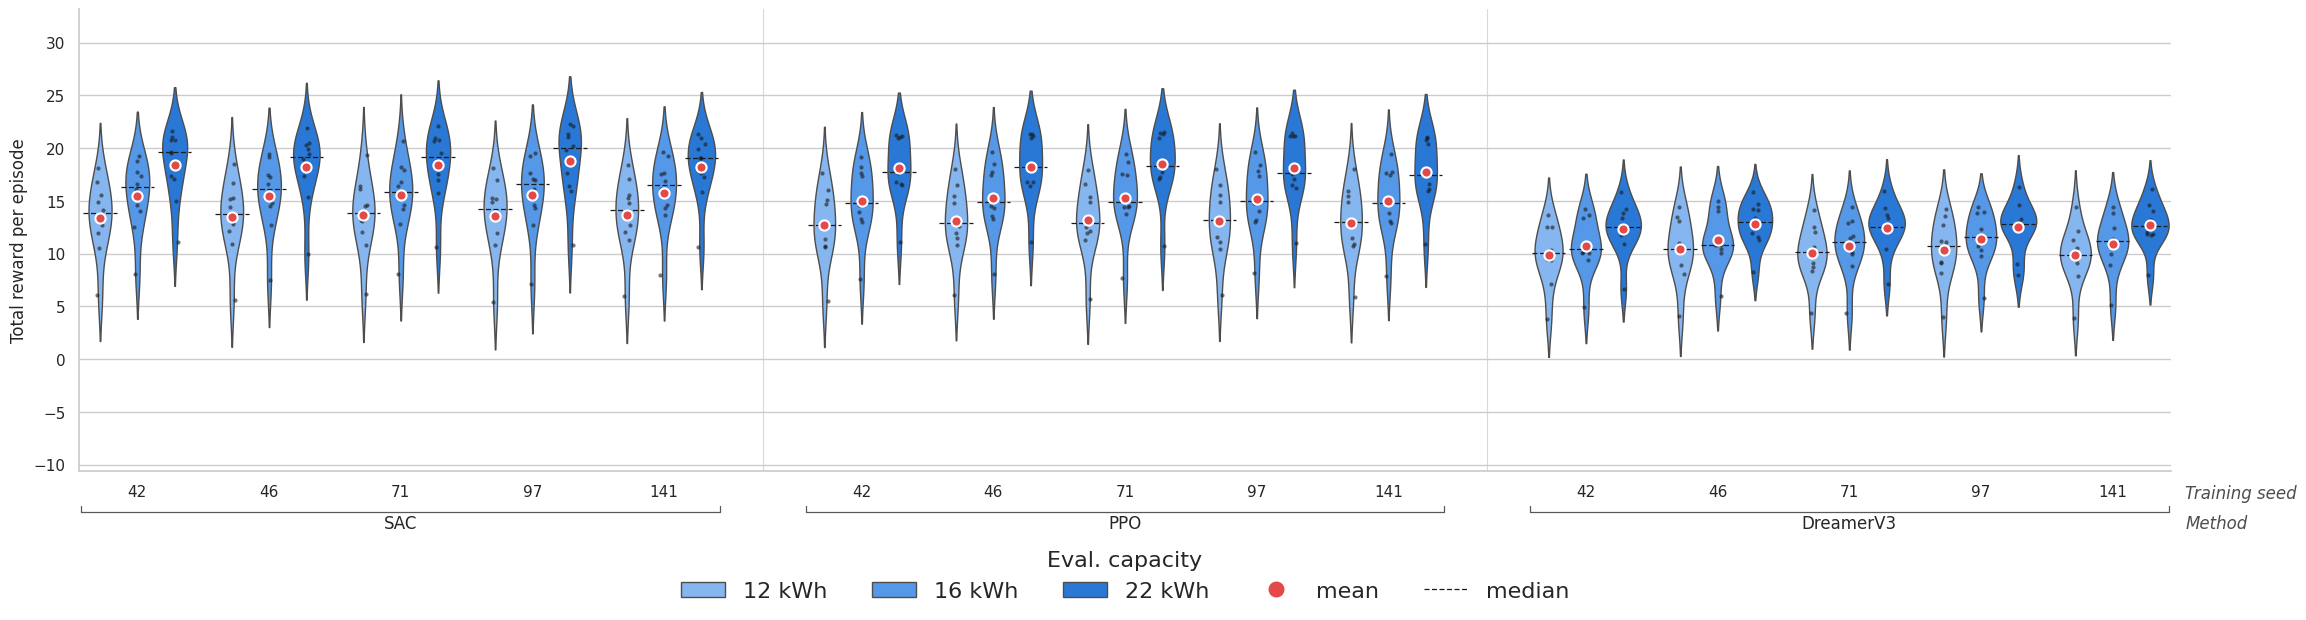

Training config: N-way  |  total_reward  |  x: Method › Training seed › Eval. capacity  ->  saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/20261028_131344_out_4.pdf


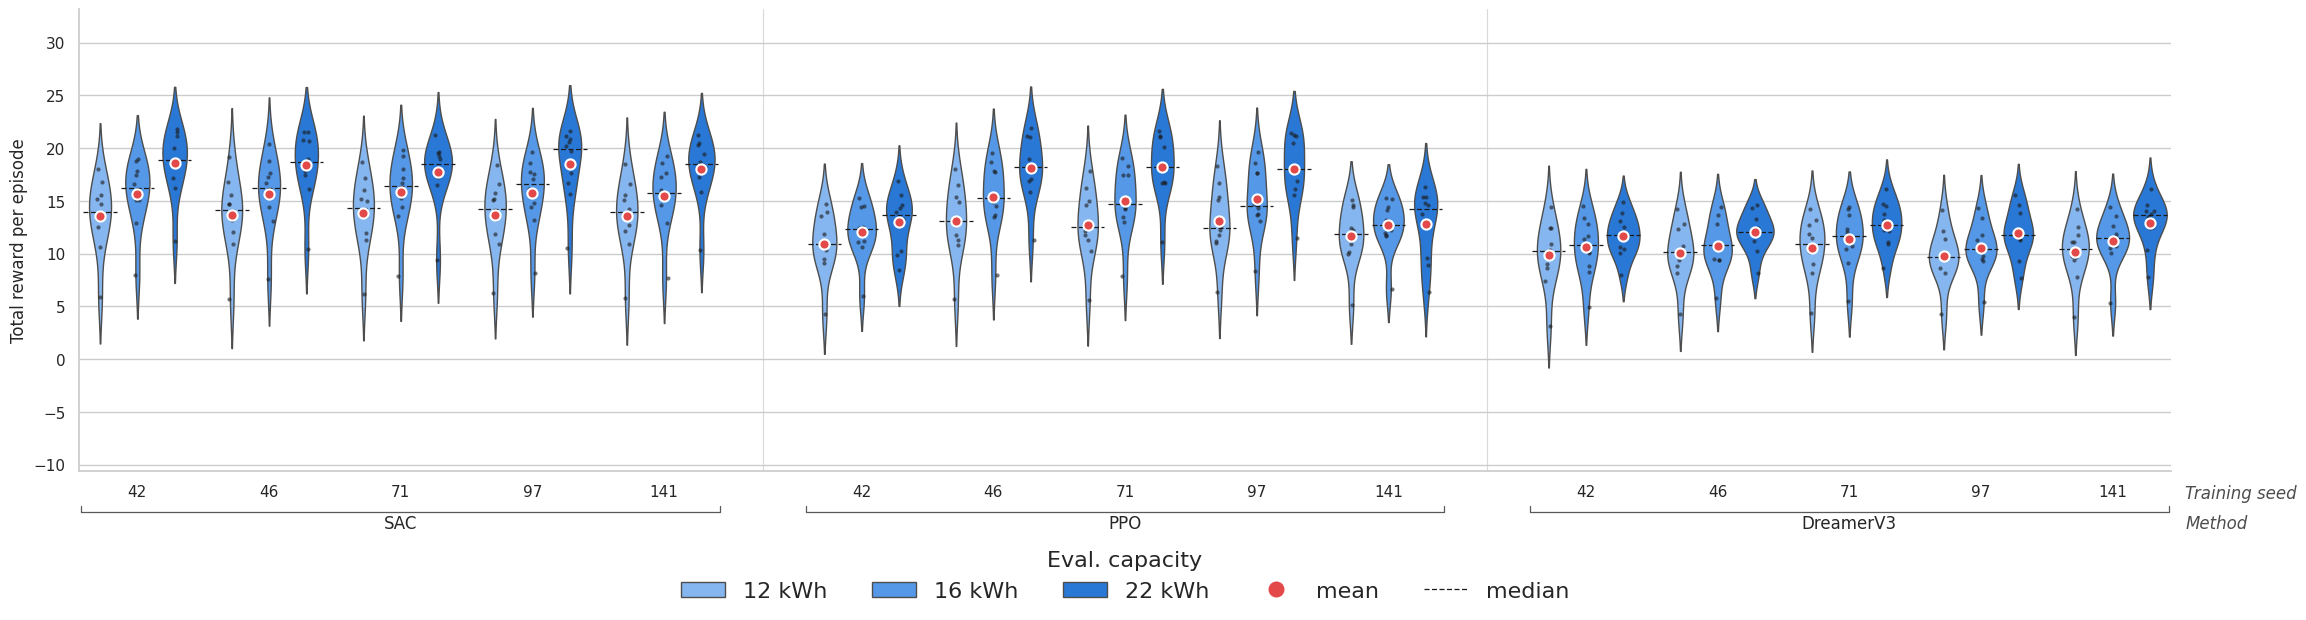

In [7]:
for metric in METRICS:
    for order in AXIS_ORDERS:
        violin_for_metric(metric, order)

## Statistics per violin

One row per (training config, method, eval config, training seed) — the episodes of exactly one
violin — with `mean` / `std` / `median` / `min` / `max` over those episodes. Written to
`<date>_<time>_out_<i>.csv`.

In [8]:
present_metrics = [metric for metric in METRICS if metric in episodes.columns]
violin_titles = [AXIS_TITLES[axis] for axis in (AXIS.GEN_CFG, AXIS.METHOD, AXIS.EVAL_CFG, AXIS.TRAIN_SEED)]

per_violin_stats = (
    labelled.groupby(violin_titles, observed=True)[present_metrics]
    .agg(["mean", "std", "median", "min", "max"])
)
per_violin_stats.insert(0, ("episodes", ""), labelled.groupby(violin_titles, observed=True).size())
per_violin_stats.to_csv(next_out_path("csv"), float_format="%.2f")
per_violin_stats

episodes total_reward  \
                                                                        mean   
Training config Method    Eval. capacity Training seed                         
15 kWh          SAC       12 kWh         42                  10    13.102281   
                                         46                  10    12.831909   
                                         71                  10    13.029861   
                                         97                  10    12.859084   
                                         141                 10    12.997600   
...                                                         ...          ...   
N-way           DreamerV3 22 kWh         42                  10    11.713957   
                                         46                  10    12.031773   
                                         71                  10    12.734736   
                                         97                  10    11.943415   
                                         141                 10    12.916144   

                                                                             \
                                                             std     median   
Training config Method    Eval. capacity Training seed                        
15 kWh          SAC       12 kWh         42             3.637170  13.468719   
                                         46             3.507636  12.675372   
                                         71             3.617779  12.915188   
                                         97             3.552042  13.230435   
                                         141            3.554412  13.012377   
...                                                          ...        ...   
N-way           DreamerV3 22 kWh         42             2.003662  11.811553   
                                         46             1.907220  12.070119   
                                         71             2.194480  12.713388   
                                         97             2.343807  11.748058   
                                         141            2.372493  13.621930   

                                                                             
                                                             min        max  
Training config Method    Eval. capacity Training seed                       
15 kWh          SAC       12 kWh         42             5.083013  17.976304  
                                         46             5.208424  17.519446  
                                         71             5.607298  18.682099  
                                         97             5.215852  17.304692  
                                         141            5.390012  18.340616  
...                                                          ...        ...  
N-way           DreamerV3 22 kWh         42             8.023188  14.871177  
                                         46             8.191241  14.657459  
                                         71             8.659221  16.165224  
                                         97             7.714785  15.551005  
                                         141            7.744988  16.120695  

[180 rows x 6 columns]

## Spread across training seeds

Collapses the training seeds: one row per (training config, method, eval config). `mean` /
`std` / `min` / `max` summarise the per-seed **means**, so `std` is the seed-to-seed spread
(small = the method trains reproducibly); `mean_of_stds` averages each seed's episode `std`,
i.e. the typical spread inside one seed. `std` is `NaN` when only one seed is left. Written to
`<date>_<time>_out_<i>.csv`.

In [9]:
group_titles = [AXIS_TITLES[axis] for axis in (AXIS.GEN_CFG, AXIS.METHOD, AXIS.EVAL_CFG)]
per_seed = (
    labelled.groupby(group_titles + [AXIS_TITLES[AXIS.TRAIN_SEED]], observed=True)[present_metrics]
    .agg(["mean", "std"])
)
seed_means = per_seed.xs("mean", axis=1, level=1)  # per-seed mean, index (group..., seed)
seed_stds = per_seed.xs("std", axis=1, level=1)    # per-seed episode std

summaries = {
    "mean": seed_means.groupby(level=group_titles, observed=True).mean(),
    "std": seed_means.groupby(level=group_titles, observed=True).std(),
    "min": seed_means.groupby(level=group_titles, observed=True).min(),
    "max": seed_means.groupby(level=group_titles, observed=True).max(),
    "mean_of_stds": seed_stds.groupby(level=group_titles, observed=True).mean(),
}
across_seed_stats = pd.concat(summaries, axis=1)
across_seed_stats.columns = across_seed_stats.columns.swaplevel(0, 1)  # -> (metric, summary)
across_seed_stats = across_seed_stats.reindex(columns=present_metrics, level=0)
across_seed_stats = across_seed_stats.reindex(columns=list(summaries), level=1)
across_seed_stats.insert(0, ("seeds", ""), seed_means.groupby(level=group_titles, observed=True).size())
across_seed_stats.to_csv(next_out_path("csv"), float_format="%.2f")
across_seed_stats

seeds total_reward            \
                                                       mean       std   
Training config Method    Eval. capacity                                
15 kWh          SAC       12 kWh             5    12.964147  0.115156   
                          16 kWh             5    15.933273  0.279895   
                          22 kWh             5    16.191296  2.643123   
                PPO       12 kWh             5    12.907171  0.233010   
                          16 kWh             5    15.197336  0.144148   
                          22 kWh             5    17.649241  0.427593   
                DreamerV3 12 kWh             5    10.217700  0.464768   
                          16 kWh             5    11.594966  0.640822   
                          22 kWh             5    13.843171  0.858195   
17 kWh          SAC       12 kWh             5    12.483233  0.657609   
                          16 kWh             5    15.450818  0.243288   
                          22 kWh             5    17.892015  1.798668   
                PPO       12 kWh             5    12.571751  0.275886   
                          16 kWh             5    14.848893  0.221667   
                          22 kWh             5    17.789157  0.315037   
                DreamerV3 12 kWh             5     9.723436  0.506791   
                          16 kWh             5    11.087138  0.613341   
                          22 kWh             5    13.246301  0.760277   
Gen. distr      SAC       12 kWh             5    13.543127  0.106343   
                          16 kWh             5    15.567322  0.117348   
                          22 kWh             5    18.380202  0.240683   
                PPO       12 kWh             5    12.990090  0.181920   
                          16 kWh             5    15.132337  0.155626   
                          22 kWh             5    18.130873  0.246921   
                DreamerV3 12 kWh             5    10.108004  0.267210   
                          16 kWh             5    11.040574  0.319161   
                          22 kWh             5    12.568568  0.173507   
N-way           SAC       12 kWh             5    13.659474  0.134525   
                          16 kWh             5    15.673669  0.139931   
                          22 kWh             5    18.232008  0.337463   
                PPO       12 kWh             5    12.287572  0.962368   
                          16 kWh             5    14.051869  1.570281   
                          22 kWh             5    16.022604  2.833251   
                DreamerV3 12 kWh             5    10.091894  0.300931   
                          16 kWh             5    10.900284  0.374421   
                          22 kWh             5    12.268005  0.525846   

                                                                             
                                                min        max mean_of_stds  
Training config Method    Eval. capacity                                     
15 kWh          SAC       12 kWh          12.831909  13.102281     3.573808  
                          16 kWh          15.553747  16.292976     3.605782  
                          22 kWh          13.458263  19.246364     5.291208  
                PPO       12 kWh          12.671192  13.204310     3.460958  
                          16 kWh          15.058377  15.400762     3.299276  
                          22 kWh          17.110791  18.124506     3.134316  
                DreamerV3 12 kWh           9.574722  10.810908     2.931749  
                          16 kWh          10.947576  12.566532     2.636346  
                          22 kWh          13.041521  15.042216     2.380228  
17 kWh          SAC       12 kWh          11.412652  13.130262     3.540911  
                          16 kWh          15.119418  15.695008     3.538023  
                          22 kWh          14.855027  19.135840     3.972298  
                PPO    